# Calibrated IMU G-G Plot

This notebook builds a vehicle G-G diagram (lateral acceleration versus longitudinal acceleration) from a decoded `LOG####_imu.csv`. It:

1. finds a stationary calibration window,
2. rotates and scales the inferred gravity vector to **1 g downward**,
3. subtracts gravity and the stationary gyro bias,
4. estimates and displays the vehicle-forward direction, and
5. draws both a scatter G-G plot and a magma density heatmap.

At rest, an accelerometer measures upward specific force, so the physical gravity vector is its negative. A single stationary pose can correct tilt, a common scale factor, and zero-rate gyro bias; it cannot identify independent per-axis accelerometer bias/scale or yaw. When speed data is available, yaw/forward is estimated by regressing horizontal IMU acceleration against `d(speed)/dt`. Set `FORWARD_IMU_VECTOR` when the sensor mounting direction is known.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")


## Configuration

The default `LOG0012` contains both stationary and driving data. `HEATMAP_SATURATION_COUNT = 8` means any bin containing eight or more samples uses the brightest end of the magma colormap. Keep this value between 5 and 10 for the requested low saturation point.


In [2]:
DATA_DIR = Path("VCU/June11thTestingDataLog_AfterChargingBattery")
LOG_ID = "LOG0012"

# Use None for automatic selection, or specify elapsed seconds: (start_s, end_s).
CALIBRATION_TIME_RANGE_S = None
CALIBRATION_MAX_DURATION_S = 5.0
MIN_CALIBRATION_DURATION_S = 2.0
STATIONARY_SPEED_THRESHOLD_MPH = 0.5

# Optional known forward direction in raw IMU [x, y, z] coordinates.
# Example: np.array([1.0, 0.0, 0.0]) if raw IMU +x points forward.
FORWARD_IMU_VECTOR = None
MIN_SPEED_ACCEL_MPS2 = 0.15

HEATMAP_BINS = 75
HEATMAP_SATURATION_COUNT = 8  # requested range: 5-10 samples/bin
GG_LIMIT_G = None              # None selects a robust limit from the data
MAX_SCATTER_POINTS = 50_000

ACCEL_COLS = ["accel_x_g", "accel_y_g", "accel_z_g"]
GYRO_COLS = ["gyro_x_dps", "gyro_y_dps", "gyro_z_dps"]
AXES = ["x", "y", "z"]
MPH_TO_MPS = 0.44704

if not 5 <= HEATMAP_SATURATION_COUNT <= 10:
    raise ValueError("HEATMAP_SATURATION_COUNT must be between 5 and 10")


In [3]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "VCU").is_dir() and (candidate / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


def resolve_data_dir(path):
    path = Path(path).expanduser()
    if path.is_absolute():
        return path
    repo_root = find_repo_root()
    for candidate in (Path.cwd() / path, repo_root / path, repo_root / "VCU" / path):
        if candidate.exists():
            return candidate.resolve()
    return (repo_root / path).resolve()


def load_imu_and_speed(data_dir, log_id):
    data_dir = resolve_data_dir(data_dir)
    imu_path = data_dir / f"{log_id}_imu.csv"
    if not imu_path.exists():
        raise FileNotFoundError(f"IMU log not found: {imu_path}")

    imu = pd.read_csv(imu_path)
    required = ["t_ms", *ACCEL_COLS, *GYRO_COLS]
    missing = [column for column in required if column not in imu.columns]
    if missing:
        raise ValueError(f"{imu_path.name} is missing columns: {missing}")

    for column in required:
        imu[column] = pd.to_numeric(imu[column], errors="coerce")
    imu = (
        imu.dropna(subset=required)
        .sort_values("t_ms")
        .drop_duplicates("t_ms")
        .reset_index(drop=True)
    )
    if len(imu) < 3:
        raise ValueError("At least three valid IMU samples are required")
    imu.insert(1, "elapsed_s", (imu["t_ms"] - imu["t_ms"].iloc[0]) / 1000.0)

    medium_path = data_dir / f"{log_id}_medium.csv"
    speed_source = None
    if medium_path.exists():
        medium = pd.read_csv(medium_path, usecols=lambda c: c in {"t_ms", "speed_mph"})
        if {"t_ms", "speed_mph"}.issubset(medium.columns):
            medium["t_ms"] = pd.to_numeric(medium["t_ms"], errors="coerce")
            medium["speed_mph"] = pd.to_numeric(medium["speed_mph"], errors="coerce")
            medium = medium.dropna().sort_values("t_ms").drop_duplicates("t_ms")
            if not medium.empty:
                imu["speed_mph"] = np.interp(
                    imu["t_ms"], medium["t_ms"], medium["speed_mph"],
                    left=medium["speed_mph"].iloc[0],
                    right=medium["speed_mph"].iloc[-1],
                )
                speed_source = medium_path
    return imu, imu_path, speed_source


def normalize(vector, name="vector"):
    vector = np.asarray(vector, dtype=float)
    magnitude = np.linalg.norm(vector)
    if not np.isfinite(magnitude) or magnitude <= 1e-12:
        raise ValueError(f"Cannot normalize {name}; magnitude is {magnitude}")
    return vector / magnitude


def rotation_between(source, target):
    """Return a proper rotation matrix mapping source onto target."""
    source = normalize(source, "rotation source")
    target = normalize(target, "rotation target")
    cross = np.cross(source, target)
    dot = float(np.clip(np.dot(source, target), -1.0, 1.0))
    sine = np.linalg.norm(cross)
    if sine < 1e-12:
        if dot > 0:
            return np.eye(3)
        basis = np.eye(3)[np.argmin(np.abs(source))]
        axis = normalize(np.cross(source, basis), "180-degree rotation axis")
        return -np.eye(3) + 2.0 * np.outer(axis, axis)

    x, y, z = cross
    skew = np.array([[0.0, -z, y], [z, 0.0, -x], [-y, x, 0.0]])
    return np.eye(3) + skew + (skew @ skew) * ((1.0 - dot) / sine**2)


def contiguous_segments(mask, time_s):
    mask = np.asarray(mask, dtype=bool)
    time_s = np.asarray(time_s, dtype=float)
    starts = np.flatnonzero(mask & np.r_[True, ~mask[:-1]])
    ends = np.flatnonzero(mask & np.r_[~mask[1:], True])
    return [
        {
            "start_idx": int(start),
            "end_idx": int(end),
            "start_s": float(time_s[start]),
            "end_s": float(time_s[end]),
            "duration_s": float(time_s[end] - time_s[start]),
            "samples": int(end - start + 1),
        }
        for start, end in zip(starts, ends)
    ]


def select_calibration_window(df):
    elapsed = df["elapsed_s"].to_numpy(dtype=float)
    if CALIBRATION_TIME_RANGE_S is not None:
        start_s, end_s = CALIBRATION_TIME_RANGE_S
        mask = (elapsed >= start_s) & (elapsed <= end_s)
        source = "manual elapsed-time range"
    elif "speed_mph" in df.columns:
        stationary = df["speed_mph"].abs().to_numpy() <= STATIONARY_SPEED_THRESHOLD_MPH
        candidates = [
            segment for segment in contiguous_segments(stationary, elapsed)
            if segment["duration_s"] >= MIN_CALIBRATION_DURATION_S
        ]
        if not candidates:
            raise ValueError("No sufficiently long zero-speed calibration window was found")
        selected = candidates[0]
        end_s = min(selected["start_s"] + CALIBRATION_MAX_DURATION_S, selected["end_s"])
        mask = (elapsed >= selected["start_s"]) & (elapsed <= end_s)
        source = f"first |speed| <= {STATIONARY_SPEED_THRESHOLD_MPH:g} mph segment"
    else:
        dt = np.median(np.diff(elapsed))
        window_samples = max(3, int(round(CALIBRATION_MAX_DURATION_S / dt)))
        accel_std = df[ACCEL_COLS].rolling(window_samples).std().pow(2).sum(axis=1)
        gyro_std = df[GYRO_COLS].rolling(window_samples).std().pow(2).sum(axis=1)
        score = accel_std + gyro_std / 10_000.0
        end_idx = int(score.idxmin())
        start_idx = end_idx - window_samples + 1
        mask = np.zeros(len(df), dtype=bool)
        mask[max(0, start_idx): end_idx + 1] = True
        source = "quietest fixed-duration IMU window (no speed stream)"

    mask = np.asarray(mask, dtype=bool)
    if mask.sum() < 3:
        raise ValueError("Calibration window contains fewer than three samples")
    duration_s = elapsed[mask][-1] - elapsed[mask][0]
    if duration_s < MIN_CALIBRATION_DURATION_S:
        raise ValueError(f"Calibration window is only {duration_s:.3f} s long")
    return mask, source


def estimate_forward(calibrated_linear_g, df, calibration_mask, gravity_rotation):
    horizontal = calibrated_linear_g.copy()
    horizontal[:, 2] = 0.0

    if FORWARD_IMU_VECTOR is not None:
        candidate = gravity_rotation @ np.asarray(FORWARD_IMU_VECTOR, dtype=float)
        candidate[2] = 0.0
        return normalize(candidate, "configured forward vector"), "configured raw-IMU vector", np.nan, None

    speed_accel = None
    if "speed_mph" in df.columns and df["speed_mph"].max() > STATIONARY_SPEED_THRESHOLD_MPH:
        elapsed = df["elapsed_s"].to_numpy(dtype=float)
        dt = np.median(np.diff(elapsed))
        smooth_samples = max(3, int(round(0.5 / dt)))
        if smooth_samples % 2 == 0:
            smooth_samples += 1
        speed_mps = df["speed_mph"].to_numpy(dtype=float) * MPH_TO_MPS
        speed_smooth = (
            pd.Series(speed_mps)
            .rolling(smooth_samples, center=True, min_periods=1)
            .mean()
            .to_numpy()
        )
        speed_accel = np.gradient(speed_smooth, elapsed)
        usable = (
            ~calibration_mask
            & np.isfinite(speed_accel)
            & (np.abs(speed_accel) >= MIN_SPEED_ACCEL_MPS2)
        )
        if usable.sum() >= 20:
            response = speed_accel[usable]
            coefficient = np.sum(horizontal[usable] * response[:, None], axis=0) / np.sum(response**2)
            if np.linalg.norm(coefficient) > 1e-9:
                forward = normalize(coefficient, "speed-regression forward vector")
                longitudinal_mps2 = (horizontal[usable] @ forward) * 9.80665
                correlation = float(np.corrcoef(longitudinal_mps2, response)[0, 1])
                return forward, "horizontal acceleration vs. d(speed)/dt regression", correlation, speed_accel

    active = (~calibration_mask) & np.isfinite(horizontal).all(axis=1)
    samples = horizontal[active]
    samples = samples[np.linalg.norm(samples, axis=1) > 1e-4]
    if len(samples) < 2:
        raise ValueError("Not enough dynamic acceleration to estimate vehicle forward")
    _, _, vh = np.linalg.svd(samples - samples.mean(axis=0), full_matrices=False)
    forward = normalize(vh[0], "PCA forward vector")
    raw_x_in_calibrated_frame = gravity_rotation @ np.array([1.0, 0.0, 0.0])
    raw_x_in_calibrated_frame[2] = 0.0
    if np.linalg.norm(raw_x_in_calibrated_frame) > 1e-9 and np.dot(forward, raw_x_in_calibrated_frame) < 0:
        forward = -forward
    return forward, "horizontal-acceleration PCA (sign toward raw IMU +x)", np.nan, speed_accel


def decorate_gg_axis(ax, limit_g):
    ax.axhline(0.0, color="0.35", linewidth=0.8)
    ax.axvline(0.0, color="0.35", linewidth=0.8)
    for radius in np.arange(0.5, limit_g + 0.01, 0.5):
        ax.add_patch(Circle((0, 0), radius, fill=False, color="0.55", linewidth=0.7, alpha=0.5))
    ax.set(xlim=(-limit_g, limit_g), ylim=(-limit_g, limit_g))
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Lateral acceleration (g, +left)")
    ax.set_ylabel("Longitudinal acceleration (g, +forward)")


## Load the IMU and select a stationary interval


In [4]:
imu, imu_path, speed_path = load_imu_and_speed(DATA_DIR, LOG_ID)
calibration_mask, calibration_source = select_calibration_window(imu)
calibration = imu.loc[calibration_mask].copy()

print(f"Loaded {len(imu):,} IMU samples from {imu_path}")
print(f"Duration: {imu['elapsed_s'].iloc[-1]:.2f} s")
print(f"Speed stream: {speed_path if speed_path is not None else 'not available'}")
print(f"Calibration selection: {calibration_source}")
print(
    f"Calibration window: {calibration['elapsed_s'].iloc[0]:.3f} to "
    f"{calibration['elapsed_s'].iloc[-1]:.3f} s ({len(calibration):,} samples)"
)


Loaded 95,211 IMU samples from C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery\LOG0012_imu.csv
Duration: 1066.28 s
Speed stream: C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery\LOG0012_medium.csv
Calibration selection: first |speed| <= 0.5 mph segment
Calibration window: 0.000 to 4.994 s (500 samples)


## Calibrate gravity, gyro bias, and vehicle axes

The negative of the stationary accelerometer mean estimates physical gravity and is mapped to `[0, 0, -1] g`. The stationary accelerometer specific force therefore maps to `[0, 0, +1] g`; adding gravity yields approximately zero linear acceleration at rest. Vehicle lateral is positive left and longitudinal is positive forward.


In [5]:
raw_accel_g = imu[ACCEL_COLS].to_numpy(dtype=float)
raw_gyro_dps = imu[GYRO_COLS].to_numpy(dtype=float)
stationary_accel_mean_g = calibration[ACCEL_COLS].mean().to_numpy(dtype=float)
stationary_gravity_raw_g = -stationary_accel_mean_g
stationary_gyro_bias_dps = calibration[GYRO_COLS].mean().to_numpy(dtype=float)
measured_gravity_g = np.linalg.norm(stationary_accel_mean_g)
accel_scale = 1.0 / measured_gravity_g
target_down = np.array([0.0, 0.0, -1.0])
gravity_rotation = rotation_between(stationary_gravity_raw_g, target_down)

calibrated_accel_g = (gravity_rotation @ (raw_accel_g * accel_scale).T).T
linear_accel_g = calibrated_accel_g + target_down
calibrated_gyro_dps = raw_gyro_dps - stationary_gyro_bias_dps

forward_cal, forward_method, forward_correlation, speed_accel_mps2 = estimate_forward(
    linear_accel_g, imu, calibration_mask, gravity_rotation
)
forward_cal[2] = 0.0
forward_cal = normalize(forward_cal, "horizontal forward")
up_cal = -target_down
left_cal = normalize(np.cross(up_cal, forward_cal), "vehicle left")
down_cal = target_down.copy()

imu_calibrated = imu.copy()
for column, values in zip(["accel_forward_g", "accel_left_g", "accel_up_g"], [
    linear_accel_g @ forward_cal,
    linear_accel_g @ left_cal,
    linear_accel_g @ up_cal,
]):
    imu_calibrated[column] = values
for axis_index, axis in enumerate(AXES):
    imu_calibrated[f"accel_cal_{axis}_g"] = calibrated_accel_g[:, axis_index]
    imu_calibrated[f"gyro_cal_{axis}_dps"] = calibrated_gyro_dps[:, axis_index]

finite_gg = np.isfinite(imu_calibrated[["accel_left_g", "accel_forward_g"]]).all(axis=1)
gg_data = imu_calibrated.loc[finite_gg].copy()
robust_extent = np.nanpercentile(
    np.abs(gg_data[["accel_left_g", "accel_forward_g"]].to_numpy()), 99.5
)
gg_limit_g = float(GG_LIMIT_G) if GG_LIMIT_G is not None else max(0.5, np.ceil(robust_extent * 10) / 10)


## Calibration metrics and forward direction


In [6]:
stationary_calibrated = calibrated_accel_g[calibration_mask]
stationary_linear = linear_accel_g[calibration_mask]
stationary_gyro_cal = calibrated_gyro_dps[calibration_mask]
rotation_angle_deg = np.degrees(
    np.arccos(np.clip((np.trace(gravity_rotation) - 1.0) / 2.0, -1.0, 1.0))
)

summary_metrics = pd.DataFrame(
    [
        ("Calibration samples", int(calibration_mask.sum()), "samples"),
        ("Calibration duration", calibration['elapsed_s'].iloc[-1] - calibration['elapsed_s'].iloc[0], "s"),
        ("Measured stationary magnitude", measured_gravity_g, "g"),
        ("Common accelerometer scale", accel_scale, "multiplier"),
        ("Gravity alignment rotation", rotation_angle_deg, "deg"),
        ("Post-calibration gravity magnitude", np.linalg.norm(-stationary_calibrated.mean(axis=0)), "g"),
        ("Stationary linear-acceleration RMS", np.sqrt(np.mean(stationary_linear**2)), "g"),
        ("Stationary calibrated-gyro RMS", np.sqrt(np.mean(stationary_gyro_cal**2)), "deg/s"),
        ("Forward/speed-acceleration correlation", forward_correlation, "Pearson r"),
    ],
    columns=["metric", "value", "units"],
).set_index("metric")

axis_metrics = pd.DataFrame(
    {
        "raw stationary mean (g)": stationary_accel_mean_g,
        "raw stationary std (g)": calibration[ACCEL_COLS].std(ddof=1).to_numpy(),
        "calibrated specific-force mean (g)": stationary_calibrated.mean(axis=0),
        "calibrated stationary std (g)": stationary_calibrated.std(axis=0, ddof=1),
        "linear stationary mean (g)": stationary_linear.mean(axis=0),
        "gyro bias removed (deg/s)": stationary_gyro_bias_dps,
    },
    index=["x", "y", "z"],
)
rotation_table = pd.DataFrame(
    gravity_rotation, index=["cal x", "cal y", "cal z"], columns=["raw x", "raw y", "raw z"]
)

forward_raw = normalize(gravity_rotation.T @ forward_cal, "raw-frame forward")
left_raw = normalize(gravity_rotation.T @ left_cal, "raw-frame left")
up_raw = normalize(gravity_rotation.T @ up_cal, "raw-frame up")
down_raw = -up_raw
direction_table = pd.DataFrame(
    {
        "forward": forward_raw,
        "left": left_raw,
        "up": up_raw,
        "down / gravity": down_raw,
    },
    index=["raw IMU x", "raw IMU y", "raw IMU z"],
)

print(f"Forward-direction method: {forward_method}")
if np.isfinite(forward_correlation):
    print(f"Forward vs. d(speed)/dt correlation: {forward_correlation:.3f}")
print("Forward direction in raw IMU coordinates: " + np.array2string(forward_raw, precision=6))
print("\nCalibration summary")
display(summary_metrics)
print("Per-axis stationary metrics")
display(axis_metrics)
print("Gravity-alignment rotation (calibrated = R @ scaled_raw)")
display(rotation_table)
print("Vehicle basis expressed in raw IMU coordinates")
display(direction_table)


Forward-direction method: horizontal acceleration vs. d(speed)/dt regression
Forward vs. d(speed)/dt correlation: 0.443
Forward direction in raw IMU coordinates: [-0.977586 -0.049993  0.204516]

Calibration summary


,value,units
metric,,
Calibration samples,500.000000,samples
Calibration duration,4.994000,s
Measured stationary magnitude,0.912129,g
Common accelerometer scale,1.096336,multiplier
Gravity alignment rotation,12.211138,deg
Post-calibration gravity magnitude,1.000000,g
Stationary linear-acceleration RMS,0.033749,g
Stationary calibrated-gyro RMS,1.580408,deg/s
Forward/speed-acceleration correlation,0.442529,Pearson r


Per-axis stationary metrics


,raw stationary mean (g),raw stationary std (g),calibrated specific-force mean (g),calibrated stationary std (g),linear stationary mean (g),gyro bias removed (deg/s)
x,0.188586,0.038063,0.000000,0.047631,0.000000,-6.251340
y,-0.040703,0.009081,0.000000,0.010406,0.000000,7.831780
z,0.891492,0.036294,1.000000,0.032353,-0.000000,-0.048560


Gravity-alignment rotation (calibrated = R @ scaled_raw)


,raw x,raw y,raw z
cal x,0.978382,0.004666,-0.206754
cal y,0.004666,0.998993,0.044624
cal z,0.206754,-0.044624,0.977375


Vehicle basis expressed in raw IMU coordinates


,forward,left,up,down / gravity
raw IMU x,-0.977586,0.039736,0.206754,-0.206754
raw IMU y,-0.049993,-0.997752,-0.044624,0.044624
raw IMU z,0.204516,-0.053960,0.977375,-0.977375


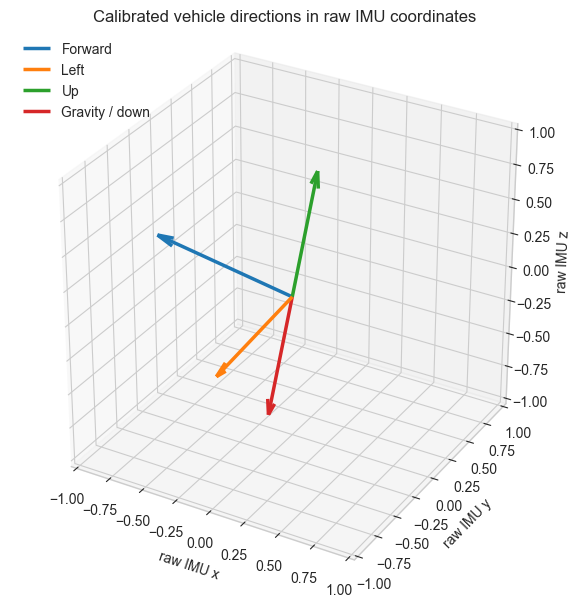

In [7]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
for vector, color, label in [
    (forward_raw, "tab:blue", "Forward"),
    (left_raw, "tab:orange", "Left"),
    (up_raw, "tab:green", "Up"),
    (down_raw, "tab:red", "Gravity / down"),
]:
    ax.quiver(0, 0, 0, *vector, color=color, linewidth=2.5, arrow_length_ratio=0.12, label=label)
ax.set(
    xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1),
    xlabel="raw IMU x", ylabel="raw IMU y", zlabel="raw IMU z",
    title="Calibrated vehicle directions in raw IMU coordinates",
)
ax.set_box_aspect((1, 1, 1))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


## Calibrated G-G scatter plot


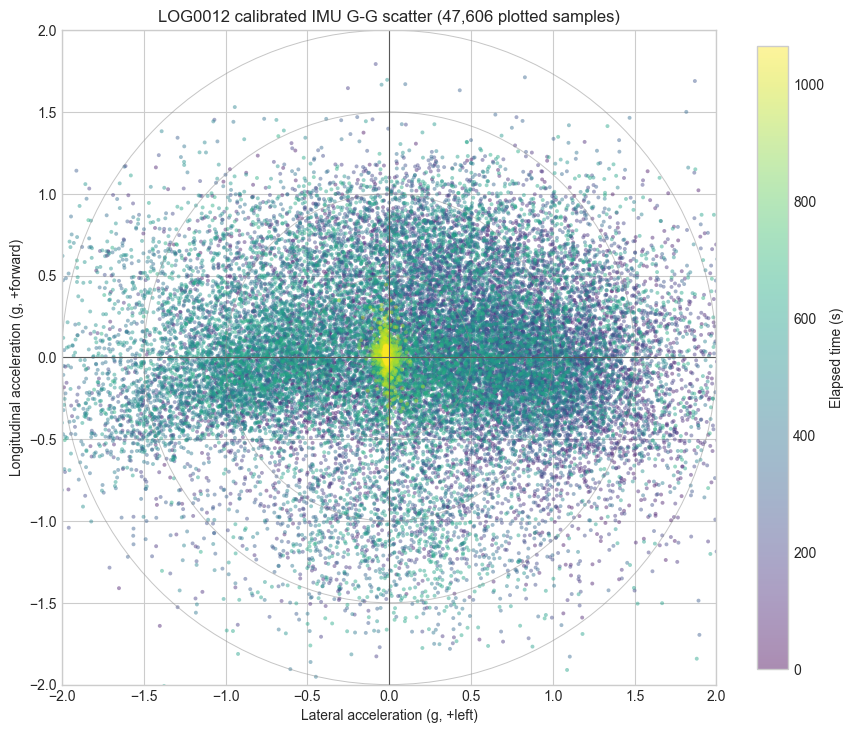

In [8]:
stride = max(1, int(np.ceil(len(gg_data) / MAX_SCATTER_POINTS)))
scatter_data = gg_data.iloc[::stride]

fig, ax = plt.subplots(figsize=(9, 8))
points = ax.scatter(
    scatter_data["accel_left_g"],
    scatter_data["accel_forward_g"],
    c=scatter_data["elapsed_s"],
    cmap="viridis",
    s=8,
    alpha=0.45,
    linewidths=0,
)
decorate_gg_axis(ax, gg_limit_g)
ax.set_title(f"{LOG_ID} calibrated IMU G-G scatter ({len(scatter_data):,} plotted samples)")
fig.colorbar(points, ax=ax, label="Elapsed time (s)", shrink=0.82)
plt.tight_layout()
plt.show()


## Magma G-G density heatmap

Zero-count bins are transparent. The color scale clips at `HEATMAP_SATURATION_COUNT` (default: 8 samples), deliberately making low-density structure visible.


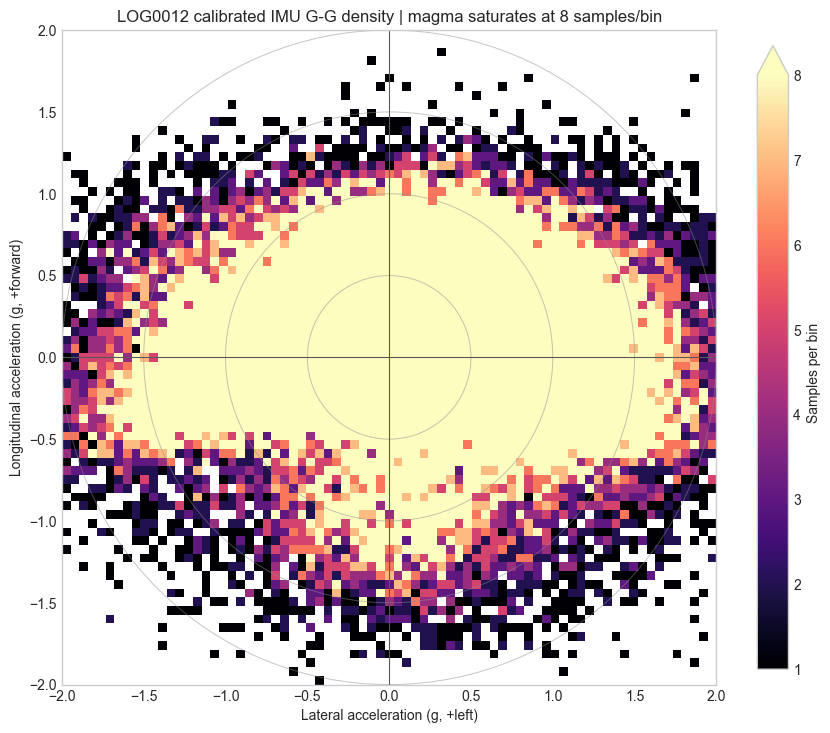

In [12]:
histogram, lateral_edges, longitudinal_edges = np.histogram2d(
    gg_data["accel_left_g"],
    gg_data["accel_forward_g"],
    bins=HEATMAP_BINS,
    range=[[-gg_limit_g, gg_limit_g], [-gg_limit_g, gg_limit_g]],
)
masked_histogram = np.ma.masked_equal(histogram.T, 0)
magma = plt.colormaps["magma"].copy()
# magma = plt.colormaps["afmhot"].copy()
magma.set_bad(alpha=0.0)
# magma.set_bad('black')

fig, ax = plt.subplots(figsize=(9, 8))
mesh = ax.pcolormesh(
    lateral_edges,
    longitudinal_edges,
    masked_histogram,
    cmap=magma,
    norm=Normalize(vmin=1, vmax=HEATMAP_SATURATION_COUNT, clip=True),
    shading="flat",
)
decorate_gg_axis(ax, gg_limit_g)
ax.set_title(
    f"{LOG_ID} calibrated IMU G-G density | magma saturates at "
    f"{HEATMAP_SATURATION_COUNT} samples/bin"
)
colorbar = fig.colorbar(mesh, ax=ax, label="Samples per bin", shrink=0.82, extend="max")
colorbar.set_ticks(np.arange(1, HEATMAP_SATURATION_COUNT + 1))
plt.tight_layout()
plt.show()


### Reading the plots

- Right/left position is lateral acceleration; positive values are left turns.
- Up/down position is longitudinal acceleration; positive values are acceleration in the estimated forward direction.
- The scatter color shows when a sample occurred.
- The heatmap shows occupancy, with bins at or above the configured 5–10 sample saturation count sharing the brightest color.
- If the reported forward method is the PCA fallback, verify the direction against the physical sensor mounting and set `FORWARD_IMU_VECTOR` when necessary.
